# Subject-Wise EEGNet Experiment

**Current notebook scope:** this file contains the original binary `T1` versus `T2` imagined unilateral-fist EEGNet baseline. Its results are saved under `outputs_subject_wise`.

**All-task adaptive sparse-channel scope:** the expanded experiment is kept in the separate files `all_tasks_adaptive_sparse_common.py` and `run_all_tasks_subject_wise.py`. It evaluates four task families separately and selects sparse channels using training trials only. It does not overwrite this baseline.

**Protocol:** use the same EEGNet architecture independently for each participant. Each subject is split into train, validation, and test trials.

**Task:** binary left-fist (`T1`) versus right-fist (`T2`) motor imagery.

In [8]:
%pip install mne numpy pandas matplotlib scikit-learn torch -q

from pathlib import Path
import copy
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
mne.set_log_level('WARNING')
DATA_DIR = Path(r'C:\SEM_7\PhaseProject\eeg-motor-movementimagery-dataset-1.0.0\files')
OUT_DIR = DATA_DIR.parent / 'outputs_subject_wise'
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS = [4, 8, 12]
SUBJECT_WISE_SUBJECTS = range(1, 21)
assert DATA_DIR.is_dir(), f'Missing dataset directory: {DATA_DIR}'
print('Protocol: subject-wise')
print('Dataset:', DATA_DIR)
print('Outputs:', OUT_DIR)

Note: you may need to restart the kernel to use updated packages.
Protocol: subject-wise
Dataset: C:\SEM_7\PhaseProject\eeg-motor-movementimagery-dataset-1.0.0\files
Outputs: C:\SEM_7\PhaseProject\eeg-motor-movementimagery-dataset-1.0.0\outputs_subject_wise



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Loading and preprocessing

Runs 4, 8, and 12 contain the two-class motor-imagery task. Every subject receives the same preprocessing: 8-30 Hz band-pass, common-average reference, baseline correction, and a 1-4 second classification window.

In [2]:
def load_subject_raw(subject_id):
    raws = []
    subject_dir = DATA_DIR / f'S{subject_id:03d}'
    for run in RUNS:
        path = subject_dir / f'S{subject_id:03d}R{run:02d}.edf'
        if path.exists():
            raws.append(mne.io.read_raw_edf(path, preload=True, verbose=False))
    if not raws: return None
    raw = mne.concatenate_raws(raws)
    if raw.info['sfreq'] != 160.0: raw.resample(160.0, npad='auto', verbose=False)
    raw.rename_channels(lambda name: name.strip('.'))
    raw.set_montage('standard_1005', on_missing='ignore')
    return raw

def make_epochs(raw):
    raw.filter(8.0, 30.0, fir_design='firwin', skip_by_annotation='edge', verbose=False)
    raw.set_eeg_reference('average', projection=False, verbose=False)
    events, event_id = mne.events_from_annotations(raw, verbose=False)
    event_id = {name: code for name, code in event_id.items() if name in ('T1', 'T2')}
    if len(event_id) != 2: return None
    epochs = mne.Epochs(raw, events, event_id=event_id, tmin=-1.0, tmax=4.0, baseline=(-1.0, 0.0), picks='eeg', preload=True, reject_by_annotation=True, verbose=False)
    return epochs.crop(tmin=1.0, tmax=4.0)

In [3]:
# Sanity check before the full experiment.
for subject_id in (1, 2, 3):
    raw = load_subject_raw(subject_id)
    epochs = make_epochs(raw) if raw is not None else None
    if epochs is not None:
        print(f'S{subject_id:03d}: sfreq={epochs.info["sfreq"]}, channels={len(epochs.ch_names)}, epochs={len(epochs)}, classes={epochs.event_id}')
    else:
        print(f'S{subject_id:03d}: unavailable or missing both classes')

C:\Users\keert\AppData\Local\Temp\ipykernel_17060\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')


S001: sfreq=160.0, channels=64, epochs=45, classes={'T1': 2, 'T2': 3}


C:\Users\keert\AppData\Local\Temp\ipykernel_17060\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')


S002: sfreq=160.0, channels=64, epochs=45, classes={'T1': 2, 'T2': 3}


C:\Users\keert\AppData\Local\Temp\ipykernel_17060\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')


S003: sfreq=160.0, channels=64, epochs=45, classes={'T1': 2, 'T2': 3}


## 2. Per-subject trial collections

Each participant is kept as a separate dataset. No trial from one subject is used to train another subject's model.

In [4]:
subject_epochs = {}
for subject_id in SUBJECT_WISE_SUBJECTS:
    raw = load_subject_raw(subject_id)
    epochs = make_epochs(raw) if raw is not None else None
    if epochs is None or len(epochs) < 15 or len(np.unique(epochs.events[:, -1])) != 2:
        continue
    subject_epochs[subject_id] = (
        epochs.get_data(copy=False).astype(np.float32),
        epochs.events[:, -1].copy(),
    )
print('Usable subjects:', len(subject_epochs))
print('Trials per subject:', {subject_id: len(data[0]) for subject_id, data in subject_epochs.items()})

C:\Users\keert\AppData\Local\Temp\ipykernel_17060\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local\Temp\ipykernel_17060\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local\Temp\ipykernel_17060\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local\Temp\ipykernel_17060\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local

Usable subjects: 20
Trials per subject: {1: 45, 2: 45, 3: 45, 4: 45, 5: 45, 6: 45, 7: 45, 8: 45, 9: 45, 10: 45, 11: 45, 12: 45, 13: 45, 14: 45, 15: 45, 16: 45, 17: 45, 18: 45, 19: 45, 20: 45}


## 3. Same EEGNet architecture for each subject

For every subject, trials are divided into 60% training, 20% validation, and 20% test data using stratification. The test trials remain unseen until that subject's model is selected.

In [5]:
class EEGNet(nn.Module):
    def __init__(self, channels, samples, dropout=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, (1, 64), padding=(0, 32), bias=False), nn.BatchNorm2d(8),
            nn.Conv2d(8, 16, (channels, 1), groups=8, bias=False), nn.BatchNorm2d(16), nn.ELU(), nn.AvgPool2d((1, 4)), nn.Dropout(dropout),
            nn.Conv2d(16, 16, (1, 16), padding=(0, 8), groups=16, bias=False), nn.Conv2d(16, 16, (1, 1), bias=False), nn.BatchNorm2d(16), nn.ELU(), nn.AvgPool2d((1, 8)), nn.Dropout(dropout)
        )
        with torch.no_grad():
            flat_dim = self.features(torch.zeros(1, 1, channels, samples)).flatten(1).shape[1]
        self.classifier = nn.Linear(flat_dim, 2)
    def forward(self, x): return self.classifier(self.features(x).flatten(1))

def make_loader(X_data, y_data, indices, shuffle):
    normalized = (X_data[indices] - X_data[indices].mean(axis=2, keepdims=True)) / (X_data[indices].std(axis=2, keepdims=True) + 1e-6)
    data = torch.tensor(normalized, dtype=torch.float32).unsqueeze(1)
    targets = torch.tensor(y_data[indices], dtype=torch.long)
    return DataLoader(TensorDataset(data, targets), batch_size=16, shuffle=shuffle)

def train_subject_model(X_subject, y_subject):
    labels = np.sort(np.unique(y_subject))
    y_binary = (y_subject == labels[1]).astype(np.int64)
    all_indices = np.arange(len(y_binary))
    train_valid_idx, test_idx = train_test_split(all_indices, test_size=0.20, stratify=y_binary, random_state=SEED)
    train_idx, valid_idx = train_test_split(train_valid_idx, test_size=0.25, stratify=y_binary[train_valid_idx], random_state=SEED)
    train_loader = make_loader(X_subject, y_binary, train_idx, True)
    valid_loader = make_loader(X_subject, y_binary, valid_idx, False)
    test_loader = make_loader(X_subject, y_binary, test_idx, False)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = EEGNet(X_subject.shape[1], X_subject.shape[2]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-3)
    criterion = nn.CrossEntropyLoss()
    best_state = None; best_valid = -np.inf; wait = 0
    for epoch in range(80):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
        model.eval(); correct = 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                correct += (model(xb.to(device)).argmax(1).cpu() == yb).sum().item()
        valid_accuracy = correct / len(valid_loader.dataset)
        if valid_accuracy > best_valid:
            best_valid = valid_accuracy; best_state = copy.deepcopy(model.state_dict()); wait = 0
        else:
            wait += 1
        if wait >= 15: break
    model.load_state_dict(best_state); model.eval(); predictions = []; truth = []
    with torch.no_grad():
        for xb, yb in test_loader:
            predictions.extend(model(xb.to(device)).argmax(1).cpu().numpy()); truth.extend(yb.numpy())
    return np.asarray(truth), np.asarray(predictions), best_valid

In [ ]:
# Subject-wise loaders are created inside train_subject_model so each subject
# keeps its own train, validation, and test trials isolated.

## 4. Subject-wise training and evaluation

A fresh EEGNet is trained for each subject. Validation accuracy selects that subject's best model; the held-out trials are evaluated only afterward.

In [6]:
subject_results = []
all_truth = []; all_predictions = []
for subject_id, (X_subject, raw_labels) in subject_epochs.items():
    truth_subject, predictions_subject, best_valid = train_subject_model(X_subject, raw_labels)
    accuracy_subject = accuracy_score(truth_subject, predictions_subject)
    f1_subject = f1_score(truth_subject, predictions_subject, average='macro')
    subject_results.append({'subject': int(subject_id), 'validation_accuracy': float(best_valid), 'test_accuracy': float(accuracy_subject), 'macro_f1': float(f1_subject), 'n_test_trials': int(len(truth_subject))})
    all_truth.extend(truth_subject); all_predictions.extend(predictions_subject)
    print(f'S{subject_id:03d}: validation={best_valid:.3f}, test={accuracy_subject:.3f}, macro-F1={f1_subject:.3f}')
subject_results_df = pd.DataFrame(subject_results)
display(subject_results_df)
print('Mean subject-wise accuracy:', subject_results_df.test_accuracy.mean())
print('Median subject-wise accuracy:', subject_results_df.test_accuracy.median())
print('Mean subject-wise macro-F1:', subject_results_df.macro_f1.mean())
subject_results_df.to_csv(OUT_DIR / 'subject_wise_eegnet_results.csv', index=False)

S001: validation=0.667, test=0.556, macro-F1=0.500
S002: validation=0.444, test=0.444, macro-F1=0.308
S003: validation=0.889, test=0.667, macro-F1=0.649
S004: validation=0.556, test=0.556, macro-F1=0.550
S005: validation=0.556, test=0.444, macro-F1=0.444
S006: validation=0.667, test=0.444, macro-F1=0.308
S007: validation=0.556, test=0.556, macro-F1=0.357
S008: validation=0.556, test=0.444, macro-F1=0.308
S009: validation=0.778, test=0.667, macro-F1=0.649
S010: validation=0.556, test=0.556, macro-F1=0.357
S011: validation=0.889, test=0.667, macro-F1=0.649
S012: validation=0.556, test=0.556, macro-F1=0.357
S013: validation=0.667, test=0.556, macro-F1=0.357
S014: validation=0.556, test=0.444, macro-F1=0.308
S015: validation=0.333, test=0.444, macro-F1=0.308
S016: validation=0.667, test=0.556, macro-F1=0.500
S017: validation=0.444, test=0.444, macro-F1=0.416
S018: validation=0.667, test=0.556, macro-F1=0.357
S019: validation=0.556, test=0.556, macro-F1=0.357
S020: validation=0.556, test=0.

,subject,validation_accuracy,test_accuracy,macro_f1,n_test_trials
0,1,0.666667,0.555556,0.500000,9
1,2,0.444444,0.444444,0.307692,9
2,3,0.888889,0.666667,0.649351,9
3,4,0.555556,0.555556,0.550000,9
4,5,0.555556,0.444444,0.444444,9
5,6,0.666667,0.444444,0.307692,9
6,7,0.555556,0.555556,0.357143,9
7,8,0.555556,0.444444,0.307692,9
8,9,0.777778,0.666667,0.649351,9
9,10,0.555556,0.555556,0.357143,9


Mean subject-wise accuracy: 0.5333333333333333
Median subject-wise accuracy: 0.5555555555555556
Mean subject-wise macro-F1: 0.41982711732711736


## 5. Subject-wise summary

These metrics describe personalized performance and must be reported separately from the subject-independent result.

Aggregate subject-wise accuracy: 0.5333
Aggregate subject-wise macro-F1: 0.5249
              precision    recall  f1-score   support

          T1     0.5455    0.6383    0.5882        94
          T2     0.5143    0.4186    0.4615        86

    accuracy                         0.5333       180
   macro avg     0.5299    0.5285    0.5249       180
weighted avg     0.5306    0.5333    0.5277       180



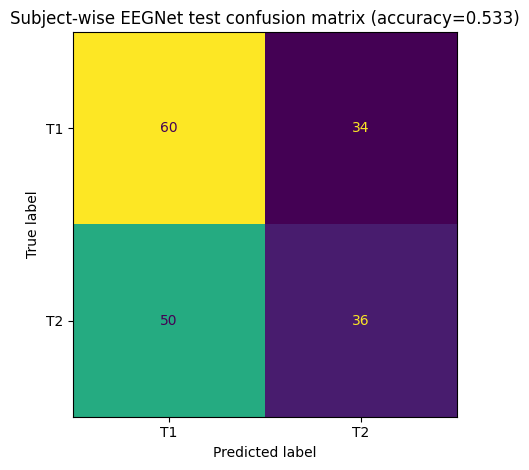

In [7]:
truth = np.asarray(all_truth); predictions = np.asarray(all_predictions)
accuracy_overall = accuracy_score(truth, predictions); f1_overall = f1_score(truth, predictions, average='macro')
print(f'Aggregate subject-wise accuracy: {accuracy_overall:.4f}')
print(f'Aggregate subject-wise macro-F1: {f1_overall:.4f}')
print(classification_report(truth, predictions, target_names=['T1', 'T2'], digits=4))
report = {'seed': SEED, 'protocol': 'subject-wise', 'accuracy_micro': float(accuracy_overall), 'macro_f1_micro': float(f1_overall), 'mean_subject_accuracy': float(subject_results_df.test_accuracy.mean()), 'median_subject_accuracy': float(subject_results_df.test_accuracy.median()), 'mean_subject_macro_f1': float(subject_results_df.macro_f1.mean()), 'subjects': [int(subject_id) for subject_id in subject_results_df.subject]}
(OUT_DIR / 'subject_wise_metrics.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
cm = confusion_matrix(truth, predictions)
ConfusionMatrixDisplay(cm, display_labels=['T1', 'T2']).plot(colorbar=False); plt.title(f'Subject-wise EEGNet test confusion matrix (accuracy={accuracy_overall:.3f})'); plt.tight_layout(); plt.savefig(OUT_DIR / 'subject_wise_confusion_matrix.png', dpi=150); plt.show()

## Research interpretation and next experiments

A result near binary chance is still informative: cross-subject EEG transfer is difficult, and effective sample size is closer to the number of independent subjects than the number of epochs. Do not claim clinical or real-time usefulness from this baseline alone.

Recommended follow-up experiments are repeated subject splits with confidence intervals, training-only channel normalization, a fixed central motor-cortex channel subset, consistent artifact handling as an ablation, and lightweight calibration using data from a new participant.